# Projet SQL — Analyse commerciale de Chinook

## Introduction

Ce projet a pour objectif d'explorer et d'analyser les données commerciales de **Chinook**, une base de données d'entraînement représentant un magasin de musique. L'analyse vise à mieux comprendre la répartition géographique de la clientèle, les revenus générés, les dépenses des clients et les ventes selon les genres musicaux.

Les données sont organisées en plusieurs tables liées entre elles, notamment `Customer`, `Invoice`, `InvoiceLine`, `Track` et `Genre`.

### Outils et méthode

- **SQLite et SQL** : interrogation des tables, jointures et calculs d'indicateurs (`COUNT`, `SUM`, `AVG`, `GROUP BY`).
- **Python et Pandas** : exécution des requêtes SQL et affichage des résultats dans Jupyter Notebook.
- **Matplotlib** : visualisation des principaux résultats.

Le notebook suit huit missions : exploration des clients, analyse des ventes par pays, étude des factures et des meilleurs clients, analyse des genres musicaux, puis visualisation et synthèse des résultats.

**Note :** Chinook est une base de démonstration ; les conclusions illustrent une démarche d'analyse et ne décrivent pas une entreprise réelle.


In [2]:
import sqlite3

connexion = sqlite3.connect(
    r"D:\DataScience\projet SQL\chinook.sqlite"
)

print("Connexion réussie !")

Connexion réussie !


In [3]:
import pandas as pd

requete = """
SELECT *
FROM Customer
LIMIT 10;
"""

resultat = pd.read_sql_query(requete, connexion)

display(resultat)

,CustomerId,FirstName,LastName,Company,Address,City,State,Country,PostalCode,Phone,Fax,Email,SupportRepId
0,1,Luís,Gonçalves,Embraer - Empresa Brasileira de Aeronáutica S.A.,"Av. Brigadeiro Faria Lima, 2170",São José dos Campos,SP,Brazil,12227-000,+55 (12) 3923-5555,+55 (12) 3923-5566,luisg@embraer.com.br,3
1,2,Leonie,Köhler,NaN,Theodor-Heuss-Straße 34,Stuttgart,NaN,Germany,70174,+49 0711 2842222,NaN,leonekohler@surfeu.de,5
2,3,François,Tremblay,NaN,1498 rue Bélanger,Montréal,QC,Canada,H2G 1A7,+1 (514) 721-4711,NaN,ftremblay@gmail.com,3
3,4,Bjørn,Hansen,NaN,Ullevålsveien 14,Oslo,NaN,Norway,0171,+47 22 44 22 22,NaN,bjorn.hansen@yahoo.no,4
4,5,František,Wichterlová,JetBrains s.r.o.,Klanova 9/506,Prague,NaN,Czech Republic,14700,+420 2 4172 5555,+420 2 4172 5555,frantisekw@jetbrains.com,4
5,6,Helena,Holý,NaN,Rilská 3174/6,Prague,NaN,Czech Republic,14300,+420 2 4177 0449,NaN,hholy@gmail.com,5
6,7,Astrid,Gruber,NaN,"Rotenturmstraße 4, 1010 Innere Stadt",Vienne,NaN,Austria,1010,+43 01 5134505,NaN,astrid.gruber@apple.at,5
7,8,Daan,Peeters,NaN,Grétrystraat 63,Brussels,NaN,Belgium,1000,+32 02 219 03 03,NaN,daan_peeters@apple.be,4
8,9,Kara,Nielsen,NaN,Sønder Boulevard 51,Copenhagen,NaN,Denmark,1720,+453 3331 9991,NaN,kara.nielsen@jubii.dk,4
9,10,Eduardo,Martins,Woodstock Discos,"Rua Dr. Falcão Filho, 155",São Paulo,SP,Brazil,01007-010,+55 (11) 3033-5446,+55 (11) 3033-4564,eduardo@woodstock.com.br,4


In [7]:
requete_factures = """
SELECT *
FROM Invoice
LIMIT 10;
"""

resultat_factures = pd.read_sql_query(
    requete_factures, connexion
)

display(resultat_factures)

,InvoiceId,CustomerId,InvoiceDate,BillingAddress,BillingCity,BillingState,BillingCountry,BillingPostalCode,Total
0,1,2,2021-01-01 00:00:00,Theodor-Heuss-Straße 34,Stuttgart,NaN,Germany,70174,1.98
1,2,4,2021-01-02 00:00:00,Ullevålsveien 14,Oslo,NaN,Norway,0171,3.96
2,3,8,2021-01-03 00:00:00,Grétrystraat 63,Brussels,NaN,Belgium,1000,5.94
3,4,14,2021-01-06 00:00:00,8210 111 ST NW,Edmonton,AB,Canada,T6G 2C7,8.91
4,5,23,2021-01-11 00:00:00,69 Salem Street,Boston,MA,USA,2113,13.86
5,6,37,2021-01-19 00:00:00,Berger Straße 10,Frankfurt,NaN,Germany,60316,0.99
6,7,38,2021-02-01 00:00:00,Barbarossastraße 19,Berlin,NaN,Germany,10779,1.98
7,8,40,2021-02-01 00:00:00,"8, Rue Hanovre",Paris,NaN,France,75002,1.98
8,9,42,2021-02-02 00:00:00,"9, Place Louis Barthou",Bordeaux,NaN,France,33000,3.96
9,10,46,2021-02-03 00:00:00,3 Chatham Street,Dublin,Dublin,Ireland,NaN,5.94


In [5]:
requete_nombre_clients = """
SELECT COUNT(*) AS nombre_clients
FROM Customer;
"""

resultat_nombre_clients = pd.read_sql_query(
    requete_nombre_clients, connexion
)

display(resultat_nombre_clients)

,nombre_clients
0,59


### Mission 1 — Analyse du nombre total de clients

**Objectif :** déterminer le nombre total de clients enregistrés dans la base de données Chinook.

**Méthode :** nous utilisons la fonction SQL `COUNT()` sur la table `Customer` afin de compter le nombre de clients.

**Résultat :** la base de données contient **59 clients**.

**Interprétation :** ce premier indicateur permet de connaître la taille de la clientèle du magasin. Il constitue un point de départ pour des analyses plus approfondies, notamment la répartition des clients par pays et l'étude de leurs achats.

In [6]:
requete_pays = """
SELECT Country,
COUNT (CustomerId) AS nombre_clients
FROM Customer
GROUP BY Country
ORDER BY nombre_clients DESC ;
"""

resultat_pays = pd.read_sql_query(requete_pays, connexion)
display(resultat_pays)

,Country,nombre_clients
0,USA,13
1,Canada,8
2,France,5
3,Brazil,5
4,Germany,4
5,United Kingdom,3
6,Portugal,2
7,India,2
8,Czech Republic,2
9,Sweden,1


### Mission 2 — Analyse de la répartition géographique des clients

**Objectif :** identifier les pays où se trouvent les clients du magasin et déterminer ceux qui possèdent le plus grand nombre de clients.

**Méthode :** nous utilisons `COUNT()` pour compter les clients, `GROUP BY` pour les regrouper par pays et `ORDER BY` pour classer les résultats par ordre décroissant.

**Résultat :** les États-Unis arrivent en première position avec **13 clients**, suivis du Canada avec **8 clients**. La France et le Brésil comptent chacun **5 clients**.

**Interprétation :** les États-Unis et le Canada représentent les deux principaux marchés en nombre de clients. Cette analyse permet de mieux comprendre la répartition géographique de la clientèle et d'identifier les marchés importants.

Cependant, un pays qui compte davantage de clients ne génère pas nécessairement plus de chiffre d'affaires. Il est donc intéressant de comparer ces résultats aux ventes réalisées dans chaque pays.

In [9]:
requete_ventes_pays = """
SELECT BillingCountry,
SUM (Total) AS chiffre_affaires
FROM Invoice
GROUP BY BillingCountry
ORDER BY chiffre_affaires  DESC ;
"""

resultat_ventes_pays = pd.read_sql_query(requete_ventes_pays, connexion)
display(resultat_ventes_pays)

,BillingCountry,chiffre_affaires
0,USA,523.06
1,Canada,303.96
2,France,195.10
3,Brazil,190.10
4,Germany,156.48
5,United Kingdom,112.86
6,Czech Republic,90.24
7,Portugal,77.24
8,India,75.26
9,Chile,46.62


### Mission 3 — Analyse du chiffre d'affaires par pays

**Objectif :** calculer le chiffre d'affaires généré dans chaque pays afin d'identifier les marchés les plus importants pour le magasin Chinook.

**Méthode :** nous utilisons `SUM(Total)` pour calculer le chiffre d'affaires, `GROUP BY BillingCountry` pour regrouper les factures par pays et `ORDER BY` pour classer les résultats par ordre décroissant.

**Résultat :** les États-Unis arrivent en première position avec un chiffre d'affaires de **523,06**, suivis du Canada (**303,96**) et de la France (**195,10**).

**Interprétation :** les États-Unis représentent le principal marché du magasin en termes de chiffre d'affaires, ce qui confirme les observations de la mission 2 concernant le nombre de clients.

Cependant, un chiffre d'affaires élevé peut s'expliquer par un nombre important de clients ou par des dépenses plus élevées. Il serait donc intéressant d'étudier le montant moyen des factures par pays afin de mieux comprendre ces différences.

In [11]:
requete_moyenne_pays = """
SELECT BillingCountry,
    AVG (Total) AS moyenne_facture
FROM Invoice
GROUP BY BillingCountry
ORDER BY moyenne_facture  DESC ;

"""

resultat_moyenne_pays = pd.read_sql_query(requete_moyenne_pays, connexion)
display(resultat_moyenne_pays)

,BillingCountry,moyenne_facture
0,Chile,6.660000
1,Ireland,6.517143
2,Hungary,6.517143
3,Czech Republic,6.445714
4,Austria,6.088571
5,Finland,5.945714
6,Netherlands,5.802857
7,India,5.789231
8,USA,5.747912
9,Norway,5.660000


### Mission 4 — Analyse du montant moyen des factures par pays

**Objectif :** calculer et comparer le montant moyen des factures dans chaque pays afin d'identifier les pays où les transactions sont les plus élevées en moyenne.

**Méthode :** nous utilisons `AVG(Total)` pour calculer la moyenne des montants des factures, `GROUP BY BillingCountry` pour regrouper les factures par pays et `ORDER BY` pour classer les résultats par ordre décroissant.

**Résultat :** le Chili présente le montant moyen par facture le plus élevé (6,66), suivi de l'Irlande et de la Hongrie (6,52 chacune).

**Interprétation :** contrairement aux États-Unis, qui génèrent le chiffre d'affaires total le plus important, le Chili possède la moyenne par facture la plus élevée. Cela montre qu'un pays ayant un chiffre d'affaires important n'est pas nécessairement celui où les factures sont les plus élevées en moyenne.

**Limite de l'analyse :** cette moyenne est calculée par facture et non par client. De plus, certains pays possèdent peu de factures, ce qui limite la portée des comparaisons.

In [16]:
requete_meilleurs_clients = """
SELECT Customer.CustomerId,
       Customer.FirstName,
       Customer.LastName,
       SUM (Invoice.Total) AS Montant_total
FROM Customer
JOIN Invoice
ON Customer.CustomerId = Invoice.CustomerId   
GROUP BY Customer.CustomerId,
       Customer.FirstName,
       Customer.LastName
ORDER BY Montant_total DESC
LIMIT 10 ;
"""

resultat_meilleurs_clients = pd.read_sql_query(requete_meilleurs_clients, connexion)
display(resultat_meilleurs_clients)

,CustomerId,FirstName,LastName,Montant_total
0,6,Helena,Holý,49.62
1,26,Richard,Cunningham,47.62
2,57,Luis,Rojas,46.62
3,45,Ladislav,Kovács,45.62
4,46,Hugh,O'Reilly,45.62
5,24,Frank,Ralston,43.62
6,28,Julia,Barnett,43.62
7,37,Fynn,Zimmermann,43.62
8,7,Astrid,Gruber,42.62
9,25,Victor,Stevens,42.62


### Mission 5 — Identification des meilleurs clients

**Objectif :** identifier les dix clients ayant généré le chiffre d'affaires le plus élevé pour le magasin Chinook.

**Méthode :** nous utilisons `JOIN` pour relier les tables `Customer` et `Invoice` grâce à `CustomerId`, puis `SUM(Invoice.Total)` pour calculer les dépenses totales de chaque client. `GROUP BY` permet de regrouper les factures par client, tandis que `ORDER BY` et `LIMIT` permettent de sélectionner les dix premiers.

**Résultat :** Helena Holý arrive en première position avec un montant total de 49,62, suivie de Richard Cunningham (47,62) et Luis Rojas (46,62).

**Interprétation :** cette analyse permet d'identifier les clients qui contribuent le plus au chiffre d'affaires. Ces informations peuvent être utilisées pour orienter des actions commerciales et des programmes de fidélisation.

**Limite :** le montant total dépensé ne permet pas, à lui seul, de mesurer la fidélité d'un client. Il serait également intéressant d'étudier le nombre et la fréquence des achats.

In [25]:
requete_activite_clients = """
SELECT Customer.CustomerId,
       Customer.FirstName,
       Customer.LastName,
       COUNT(Invoice.InvoiceId) AS nombre_factures,
       SUM (Invoice.Total) AS Montant_total
FROM Customer
JOIN Invoice
ON Customer.CustomerId = Invoice.CustomerId  
GROUP BY Customer.CustomerId,
         Customer.FirstName,
         Customer.LastName
ORDER BY nombre_factures DESC
LIMIT 10;
"""

resultat_activite_clients = pd.read_sql_query(requete_activite_clients, connexion)
display(resultat_activite_clients)

,CustomerId,FirstName,LastName,nombre_factures,Montant_total
0,1,Luís,Gonçalves,7,39.62
1,2,Leonie,Köhler,7,37.62
2,3,François,Tremblay,7,39.62
3,4,Bjørn,Hansen,7,39.62
4,5,František,Wichterlová,7,40.62
5,6,Helena,Holý,7,49.62
6,7,Astrid,Gruber,7,42.62
7,8,Daan,Peeters,7,37.62
8,9,Kara,Nielsen,7,37.62
9,10,Eduardo,Martins,7,37.62


### Mission 6 — Analyse du nombre de factures et des dépenses par client

**Objectif :** analyser l'activité des clients en comparant leur nombre de factures et le montant total de leurs achats.

**Méthode :** utilisation de `JOIN` pour relier les tables `Customer` et `Invoice`, de `COUNT()` pour compter les factures et de `SUM()` pour calculer les dépenses totales par client.

**Résultat :** les clients possèdent chacun 7 factures dans cette base de données. Cependant, leurs montants totaux d'achats sont différents. Par exemple, Helena Holý a dépensé 49,62, contre 37,62 pour Leonie Köhler.

**Interprétation :** le nombre de factures ne permet pas ici de distinguer les clients les plus actifs, puisque tous présentent la même fréquence d'achat mesurée par le nombre total de factures. En revanche, les montants dépensés permettent d'identifier les clients qui contribuent le plus au chiffre d'affaires.

**Conclusion :** pour cette base, le montant total des achats constitue un indicateur plus discriminant que le nombre de factures.

In [26]:
requete_genres = """
SELECT *
FROM Genre
LIMIT 10;
"""

display(pd.read_sql_query(requete_genres, connexion))

,GenreId,Name
0,1,Rock
1,2,Jazz
2,3,Metal
3,4,Alternative & Punk
4,5,Rock And Roll
5,6,Blues
6,7,Latin
7,8,Reggae
8,9,Pop
9,10,Soundtrack


In [27]:
requete_genres = """
SELECT *
FROM Track
LIMIT 10;
"""

display(pd.read_sql_query(requete_genres, connexion))

,TrackId,Name,AlbumId,MediaTypeId,GenreId,Composer,Milliseconds,Bytes,UnitPrice
0,1,For Those About To Rock (We Salute You),1,1,1,"Angus Young, Malcolm Young, Brian Johnson",343719,11170334,0.99
1,2,Balls to the Wall,2,2,1,"U. Dirkschneider, W. Hoffmann, H. Frank, P. Ba...",342562,5510424,0.99
2,3,Fast As a Shark,3,2,1,"F. Baltes, S. Kaufman, U. Dirkscneider & W. Ho...",230619,3990994,0.99
3,4,Restless and Wild,3,2,1,"F. Baltes, R.A. Smith-Diesel, S. Kaufman, U. D...",252051,4331779,0.99
4,5,Princess of the Dawn,3,2,1,Deaffy & R.A. Smith-Diesel,375418,6290521,0.99
5,6,Put The Finger On You,1,1,1,"Angus Young, Malcolm Young, Brian Johnson",205662,6713451,0.99
6,7,Let's Get It Up,1,1,1,"Angus Young, Malcolm Young, Brian Johnson",233926,7636561,0.99
7,8,Inject The Venom,1,1,1,"Angus Young, Malcolm Young, Brian Johnson",210834,6852860,0.99
8,9,Snowballed,1,1,1,"Angus Young, Malcolm Young, Brian Johnson",203102,6599424,0.99
9,10,Evil Walks,1,1,1,"Angus Young, Malcolm Young, Brian Johnson",263497,8611245,0.99


In [28]:
requete_genres = """
SELECT *
FROM InvoiceLine
LIMIT 10;
"""

display(pd.read_sql_query(requete_genres, connexion))


,InvoiceLineId,InvoiceId,TrackId,UnitPrice,Quantity
0,1,1,2,0.99,1
1,2,1,4,0.99,1
2,3,2,6,0.99,1
3,4,2,8,0.99,1
4,5,2,10,0.99,1
5,6,2,12,0.99,1
6,7,3,16,0.99,1
7,8,3,20,0.99,1
8,9,3,24,0.99,1
9,10,3,28,0.99,1


In [31]:
requete_ventes_genres = """
SELECT
    Genre.Name AS genre_musical,
    SUM(InvoiceLine.UnitPrice * InvoiceLine.Quantity) AS chiffre_affaires
FROM Genre
JOIN Track
    ON Genre.GenreId = Track.GenreId
JOIN InvoiceLine
    ON Track.TrackId = InvoiceLine.TrackId
GROUP BY Genre.GenreId, Genre.Name
ORDER BY chiffre_affaires DESC
LIMIT 5;
"""

resultat_genres = pd.read_sql_query(
    requete_ventes_genres, connexion
)

display(resultat_genres)

,genre_musical,chiffre_affaires
0,Rock,826.65
1,Latin,382.14
2,Metal,261.36
3,Alternative & Punk,241.56
4,TV Shows,93.53


In [32]:
import matplotlib.pyplot as plt

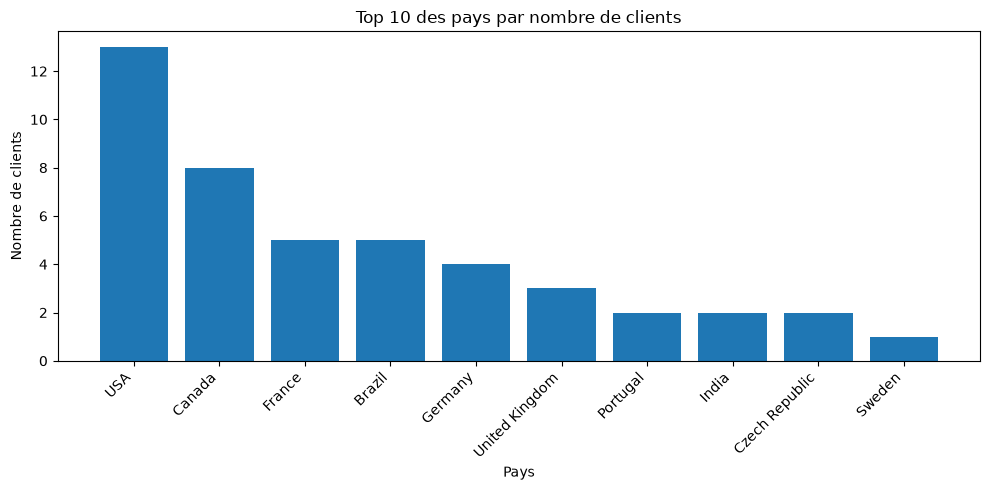

In [33]:
top10_pays = resultat_pays.head(10)

plt.figure(figsize=(10, 5))

plt.bar(
    top10_pays["Country"],
    top10_pays["nombre_clients"]
)

plt.title("Top 10 des pays par nombre de clients")
plt.xlabel("Pays")
plt.ylabel("Nombre de clients")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

**Interprétation :** ce graphique montre que les États-Unis possèdent le plus grand nombre de clients (13), suivis du Canada (8). La clientèle de Chinook est donc particulièrement représentée en Amérique du Nord.

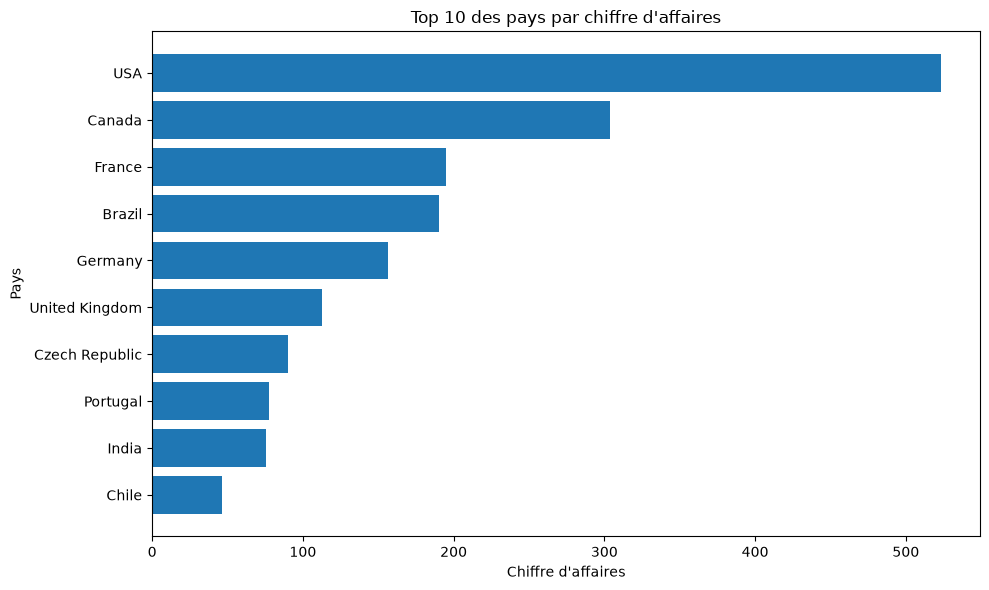

In [34]:
top10_ventes = resultat_ventes_pays.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top10_ventes["BillingCountry"],
    top10_ventes["chiffre_affaires"]
)

plt.title("Top 10 des pays par chiffre d'affaires")
plt.xlabel("Chiffre d'affaires")
plt.ylabel("Pays")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

**Interprétation :** les États-Unis génèrent le chiffre d'affaires le plus élevé (523,06), suivis du Canada (303,96). Ces résultats montrent que les deux pays ayant le plus de clients sont également ceux qui contribuent le plus au chiffre d'affaires.

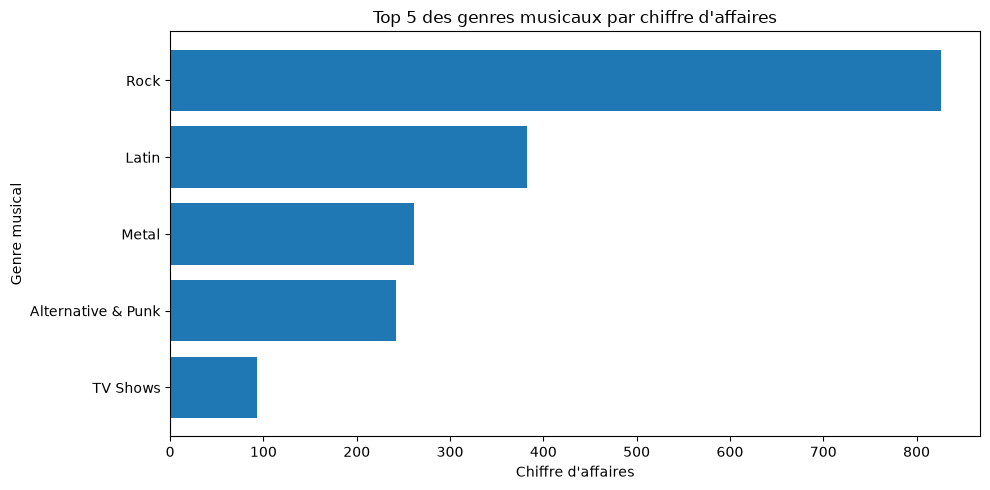

In [35]:
plt.figure(figsize=(10, 5))

plt.barh(
    resultat_genres["genre_musical"],
    resultat_genres["chiffre_affaires"]
)

plt.title("Top 5 des genres musicaux par chiffre d'affaires")
plt.xlabel("Chiffre d'affaires")
plt.ylabel("Genre musical")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

**Interprétation :** le Rock domine les ventes avec un chiffre d'affaires de 826,65, suivi du Latin (382,14) et du Metal (261,36). Le Rock constitue donc le genre musical qui génère le plus de revenus dans Chinook.

## Conclusion générale — Analyse commerciale de Chinook

Ce projet avait pour objectif d'explorer et d'analyser les données commerciales du magasin Chinook à l'aide de SQL et Python.

**Principaux résultats :**

- La base contient 59 clients.
- Les États-Unis possèdent le plus grand nombre de clients (13) et génèrent le chiffre d'affaires total le plus important.
- Le Chili présente le montant moyen par facture le plus élevé parmi les pays étudiés.
- Helena Holý est la cliente ayant réalisé le montant total d'achats le plus élevé.
- Le Rock constitue le premier genre en termes de chiffre d'affaires.

**Enseignements :**

Les analyses montrent qu'un marché possédant beaucoup de clients n'est pas nécessairement celui où les montants moyens des factures sont les plus élevés.

De même, le nombre d'achats et le montant total dépensé représentent des indicateurs différents de l'activité des clients.

**Recommandations :**

L'entreprise pourrait approfondir l'analyse de ses principaux marchés et étudier les préférences musicales de ses clients afin de mieux orienter ses actions commerciales.

**Limites :**

Les données Chinook sont des données d'entraînement. Elles ne permettent pas d'évaluer directement la rentabilité, faute d'informations sur les coûts. Les conclusions ne doivent donc pas être considérées comme représentatives d'un commerce réel.

**Compétences utilisées :** SQL (`SELECT`, `JOIN`, `GROUP BY`, `SUM`, `COUNT`, `AVG`, `ORDER BY`), SQLite, Python, Pandas et Matplotlib.